<a href="https://colab.research.google.com/github/AkramShaik-67/Deepfake_detection_using_ViT_SwinTransformer/blob/main/Deepfake_detection_using_ViT%26Swin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#import Google Drive for Dataset
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Load and explore the dataset
train_dir ='/content/drive/My Drive/Dataset/Train'
val_dir = '/content/drive/My Drive/Dataset/Validation'
test_dir = '/content/drive/My Drive/Dataset/Test'

In [ ]:
#import required modules & libires
import os
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# List all the classes
classes = os.listdir(train_dir)
num_classes = len(classes)

# Display the class names
print(f'Number of Classes: {num_classes}')
print(f'Classes: {classes}')

Number of Classes: 2
Classes: ['Fake', 'Real']


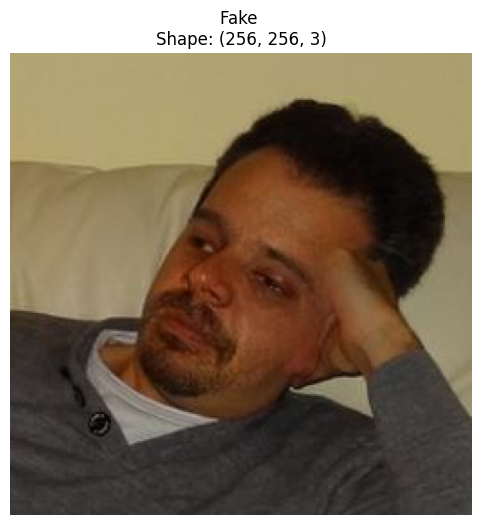

In [ ]:
# Let's visualize the images in the dataset
# Choose a random class (e.g., 'Fake' or 'Real')
random_class = random.choice(classes)

# Construct the path to the chosen class directory
random_class_path = os.path.join(train_dir, random_class)


# Get a list of all image file names in that directory
image_files = os.listdir(random_class_path)

# Choose a random image file name from the list
random_img_name = random.choice(image_files)

# Construct the full path to the random image
random_img_path = os.path.join(random_class_path, random_img_name)

# Read and display the image
random_img = plt.imread(random_img_path)

plt.figure(figsize=(6, 6))
plt.imshow(random_img)
plt.title(f'{random_class} class\nShape: {random_img.shape}')
plt.axis('off')
plt.show()

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Preprocessing
# Image dimensions and batch size
img_width, img_height = 150, 150
batch_size = 32 # there will be 32 images in a batch!

# Data generators
train_datagen = ImageDataGenerator(rescale=1./256)
val_datagen = ImageDataGenerator(rescale=1./256)
test_datagen = ImageDataGenerator(rescale=1./256)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size = (img_width, img_height),
    batch_size = batch_size,
    class_mode = 'binary',
    shuffle = True
)

val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size = (img_width, img_height),
    batch_size = batch_size,
    class_mode = 'binary',
    shuffle = True
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size = (img_width, img_height),
    batch_size = batch_size,
    class_mode = 'binary',
    shuffle = True
)

Found 70021 images belonging to 2 classes.
Found 39440 images belonging to 2 classes.
Found 10905 images belonging to 2 classes.


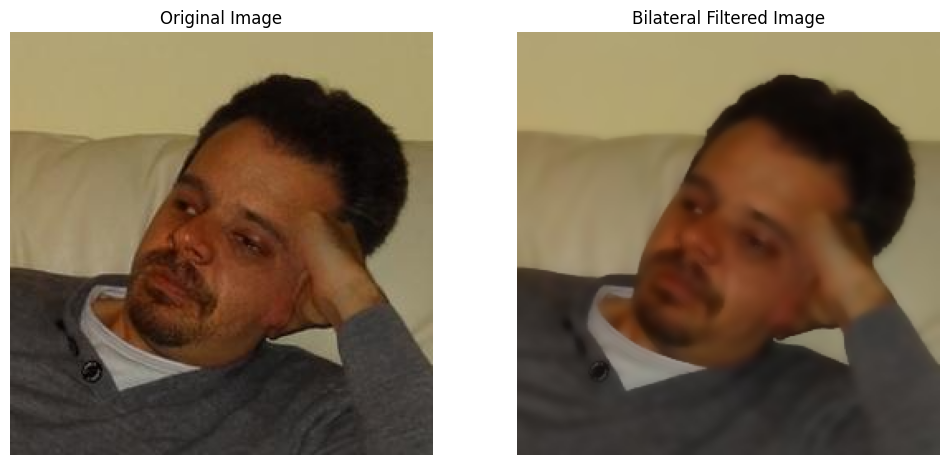

In [ ]:
# Apply bilateral filter for noise reduction while preserving edges
# d: Diameter of each pixel neighborhood that is used during filtering.
# sigmaColor: Filter sigma in the color space. A larger value of the parameter means that farther colors within the pixel neighborhood (see sigmaSpace) will be mixed together.
# sigmaSpace: Filter sigma in the coordinate space. A larger value of the parameter means that farther pixels will influence each other as long as their colors are close enough (see sigmaColor).
filtered_img = cv2.bilateralFilter(random_img, d=9, sigmaColor=100, sigmaSpace=100)

# Display the original and filtered images
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(random_img)
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(filtered_img)
plt.title('Bilateral Filtered Image')
plt.axis('off')

plt.show()